# Lab 5 PCA and super-resolution

by Szymon Skrzypczyk

For this exercise I've used the Sentinel-2 images from Lab 2 again, with forest from Puszcza Niepolomicka and built-up areas from Krakow. I added a crop of the Baltic Sea from the Gdansk acquisition listed in Lab 4. I wanted to see how these patches look in three principal components, then try rebuilding a Krakow crop after reducing its resolution by a factor of two

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import torch
from torch.nn import functional as F
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Jupyter can start in the repository root or in lab_5.
root = Path.cwd()
if root.name == "lab_5":
    root = root.parent
sys.path.insert(0, str(root / "lab_3"))
sys.path.insert(0, str(root / "lab_5"))
from lab_helpers import load_scene, rgb_display
from patch_helpers import load_water_scene, patch_features
from super_resolution import Autoencoder, bicubic, display_rgb, psnr

In [2]:
BANDS = ("blue", "green", "red", "nir")
IMAGE_DIR = root / "lab_2" / "images"
PATCH_SIZE = 16
TILE_SIZE = 48
SEED = 2026
BATCH_SIZE = 16
LEARNING_RATE = 0.001
EPOCHS = 100
EXTRA_EPOCHS = 200
AREAS = {
    "Forest": [(152, 216, 320, 384), (608, 672, 575, 639)],
    "Urban": [(298, 362, 134, 198), (379, 443, 240, 304)],
    "Sea": [(16, 80, 16, 80), (80, 144, 80, 144)],
}
COLORS = {"Forest": "forestgreen", "Urban": "firebrick", "Sea": "royalblue"}

## Selecting the patches

I picked two 64 by 64 pixel areas for each class and split each area into 16 by 16 pixel patches without overlap. That gives 32 patches per class. I chose the forest and urban areas by looking at the RGB images and checked the sea crop against the Sentinel-2 scene classification layer, which marks the entire crop as water

The sea crop is centred near 54.47° N, 18.85° E in Gdansk Bay. I kept the blue, green, red and NIR bands on the 10 m grid and aligned the scene classification layer with nearest neighbour resampling. The crop is from 14 July 2021 and starts at row 6127, column 5987 in the 10 m bands

The boxes show where I took the patches. I stretched the two land scenes for display and used a fixed scale for the sea so the stretch doesn't amplify small variations in the water. PCA uses the original band values

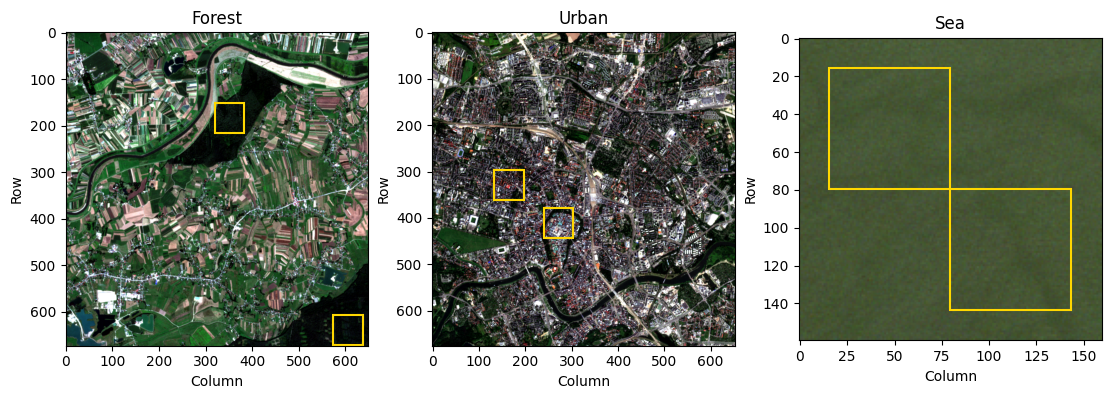

In [3]:
forest = load_scene("puszcza_niepolomicka", IMAGE_DIR, BANDS)
krakow = load_scene("krakow", IMAGE_DIR, BANDS)
sea = load_water_scene(root / "lab_5" / "gdansk_bay.tif")

scenes = {"Forest": forest, "Urban": krakow, "Sea": sea}
fig, axes = plt.subplots(1, 3, figsize=(11, 4), layout="constrained")
for ax, (label, scene) in zip(axes, scenes.items()):
    rgb = sea["cube"][..., [2, 1, 0]] / 1000 if label == "Sea" else rgb_display(scene)
    ax.imshow(rgb)
    for r0, r1, c0, c1 in AREAS[label]:
        ax.add_patch(Rectangle((c0 - 0.5, r0 - 0.5), c1 - c0, r1 - r0,
                               edgecolor="gold", facecolor="none", linewidth=1.5))
    ax.set(title=label, xlabel="Column", ylabel="Row")
plt.show()

## PCA

In Lab 4 I took the mean of red and NIR for each patch. Here I use the mean and standard deviation of all four bands, so I get eight numbers per patch. The standard deviation gives me some idea of how much the pixel values change within a patch. I standardise the eight features before fitting PCA so they are on the same scale

I fit PCA on all the selected patches and use the labels to colour the points afterwards. Each point is one patch

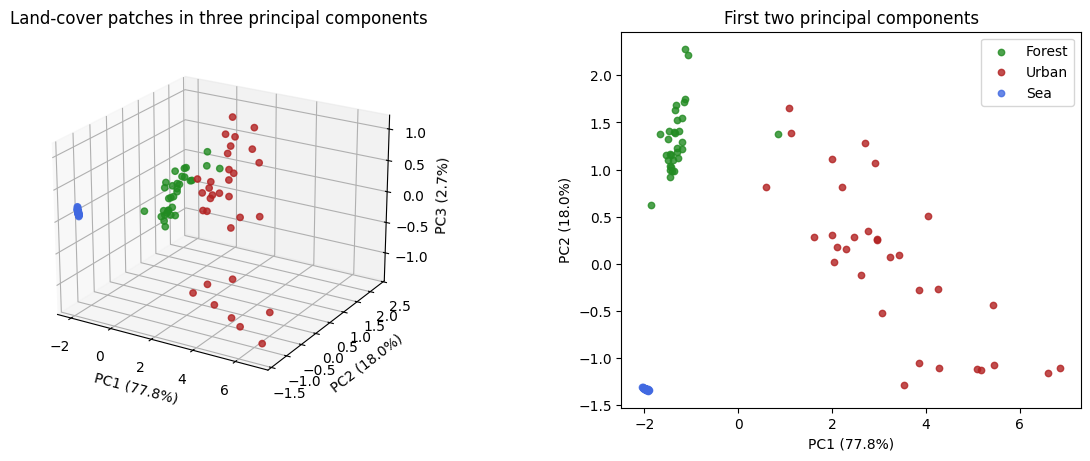

Forest: 32 patches
Urban: 32 patches
Sea: 32 patches
Variance kept: 98.5%
Silhouette score for the three labels: 0.74


In [4]:
features, labels = patch_features(scenes, AREAS, PATCH_SIZE)
scaled = StandardScaler().fit_transform(features)
pca = PCA(n_components=3)
scores = pca.fit_transform(scaled)
variance = pca.explained_variance_ratio_ * 100
axis_labels = [f"PC{i} ({part:.1f}%)" for i, part in enumerate(variance, start=1)]

fig = plt.figure(figsize=(11, 4.5), layout="constrained")
fig.get_layout_engine().set(wspace=0.20)
ax_3d = fig.add_subplot(121, projection="3d")
ax_2d = fig.add_subplot(122)
for label, color in COLORS.items():
    pc1, pc2, pc3 = scores[labels == label].T
    ax_3d.scatter(pc1, pc2, pc3, color=color, label=label, s=21, alpha=0.8)
    ax_2d.scatter(pc1, pc2, color=color, label=label, s=21, alpha=0.8)

ax_3d.set(title="Land-cover patches in three principal components",
          xlabel=axis_labels[0], ylabel=axis_labels[1], zlabel=axis_labels[2])
ax_3d.view_init(elev=22, azim=-59)
ax_2d.set(title="First two principal components",
          xlabel=axis_labels[0], ylabel=axis_labels[1])
ax_2d.legend()
plt.show()

for label in scenes:
    print(f"{label}: {np.count_nonzero(labels == label)} patches")
print(f"Variance kept: {variance.sum():.1f}%")
print(f"Silhouette score for the three labels: {silhouette_score(scores, labels):.2f}")

## PCA results

The sea patches are quite different from the other two classes. Forest and urban patches are much closer to each other, but I can still distinguish the groups in both the 3D and 2D plots

The three components keep 98.5 percent of the variance. The sea patches are very close to each other, which makes sense given they all come from one small area of open water. The urban patches spread out much more and a few of them come close to the forest group. I think the mix of roofs, roads and trees in the urban areas explains some of that spread

The silhouette score is 0.74 using the three land cover labels on the PCA plot coordinates. I selected fairly uniform patches and each class comes from a different scene, so I'd want to try this on patches from the same acquisition and on more coastlines before drawing a wider conclusion

## Super-resolution

I used the RGB bands from Krakow for this part. I trained on 48 by 48 pixel patches from the top of the image and kept a separate 192 by 192 pixel crop near the Vistula for testing. I averaged each block of 2 by 2 native pixels to make the low resolution input. That gives a 20 m input and a 10 m reference

I couldn't find the autoencoder code anywhere in upel. The Week 4 and 5 folder shown below contains an ANN diode notebook and a PCA notebook, so I defined a simple convolutional autoencoder myself to proceed with the exercise

![Week 4 and 5 materials on UPeL](upel_week4_5.png)

The encoder uses one convolutional layer to extract features from the low resolution image. I resize these features and use one convolutional decoder layer to predict a correction to a bicubic resize. I trained it by minimising the mean absolute error against the native image

I ran this section with PyTorch installed. To open Jupyter with the extra dependency from the repo root, run `uv run --with torch jupyter lab`

In [5]:
torch.manual_seed(SEED)
torch.set_num_threads(2)

# The original bands are ordered blue, green, red and NIR.
rgb = np.clip(krakow["cube"][..., [2, 1, 0]] / 10_000, 0, 1).astype(np.float32)
image = torch.from_numpy(rgb).permute(2, 0, 1)
train_image = image[:, :448]
reference = image[None, :, 480:672, 230:422]

train_hr = torch.stack([
    train_image[:, row:row + TILE_SIZE, col:col + TILE_SIZE]
    for row in range(0, train_image.shape[-2] - TILE_SIZE + 1, TILE_SIZE)
    for col in range(0, train_image.shape[-1] - TILE_SIZE + 1, TILE_SIZE)
])
train_lr = F.avg_pool2d(train_hr, kernel_size=2)
test_lr = F.avg_pool2d(reference, kernel_size=2)

print(f"Training: {len(train_hr)} patches of {TILE_SIZE} x {TILE_SIZE}")
print(f"Test: {tuple(test_lr.shape[-2:])} input to {tuple(reference.shape[-2:])} reference")

Training: 117 patches of 48 x 48
Test: (96, 96) input to (192, 192) reference


In [6]:
model = Autoencoder()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

for epoch in range(1, EPOCHS + 1):
    total_loss = 0.0
    for batch in torch.randperm(len(train_hr)).split(BATCH_SIZE):
        optimizer.zero_grad()
        loss = F.l1_loss(model(train_lr[batch]), train_hr[batch])
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(batch)
    if epoch == 1 or epoch % 25 == 0:
        print(f"Epoch {epoch:3d}: training MAE {total_loss / len(train_hr):.5f}")

model.eval()
with torch.no_grad():
    prediction = model(test_lr).clamp(0, 1)
baseline = bicubic(test_lr).clamp(0, 1)

Epoch   1: training MAE 0.01121


Epoch  25: training MAE 0.00921


Epoch  50: training MAE 0.00912


Epoch  75: training MAE 0.00908


Epoch 100: training MAE 0.00907


## Test crop

I compared both reconstructions with the original crop using PSNR. Higher PSNR means a smaller squared error against the original pixels. The display uses the same RGB stretch for all four images, and the bottom row shows the same small area in more detail

The decibels come from the `psnr()` function, which calculates the peak signal-to-noise ratio (PSNR), hence the use of decibels

Bicubic:     36.86 dB
Autoencoder: 37.23 dB


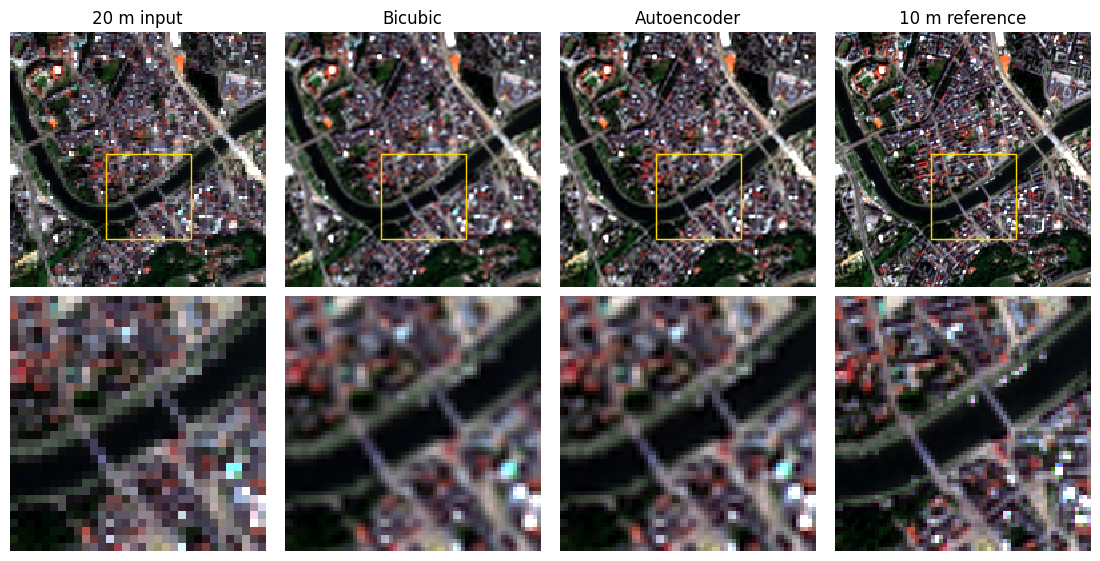

In [7]:
print(f"Bicubic:     {psnr(baseline, reference):.2f} dB")
print(f"Autoencoder: {psnr(prediction, reference):.2f} dB")

# Use one display stretch from the training area for all four panels.
lo, hi = np.percentile(train_image.numpy(), [2, 98], axis=(1, 2))
nearest = F.interpolate(test_lr, scale_factor=2, mode="nearest")
views = {
    "20 m input": nearest, "Bicubic": baseline,
    "Autoencoder": prediction, "10 m reference": reference,
}
fig, axes = plt.subplots(2, 4, figsize=(11, 5.5), layout="constrained")
zoom = np.s_[92:156, 72:136]
for (title, pixels), (full, detail) in zip(views.items(), axes.T):
    display_pixels = display_rgb(pixels, lo, hi)
    full.imshow(display_pixels, interpolation="nearest")
    full.add_patch(Rectangle((71.5, 91.5), 64, 64, edgecolor="gold", facecolor="none"))
    full.set_title(title)
    detail.imshow(display_pixels[zoom], interpolation="nearest")
    full.axis("off")
    detail.axis("off")
plt.show()

## Super-resolution results

The autoencoder reached 37.23 dB on the test crop, compared with 36.86 dB for bicubic. It's a small difference. The zoom shows that the reconstruction is still blurred compared with the original, especially around the roofs

The model gives me a 192 by 192 image from a 96 by 96 input and recovers some of the detail I lost when I made the 20 m copy. Both crops come from the same Sentinel-2 scene, so I'll try another crop in the extras section :) I'd still like to test a different acquisition

I'd start with more training patches from different cities and test on a city I left out. I'd also try blurring the 10 m image with a filter that matches the sensor before downsampling. The 2 by 2 averages are easy to make, but actual 20 m pixels can blur across those block boundaries

## Extras

I trained the same autoencoder again from scratch for 200 epochs using the same training patches. I kept the random seed and other settings the same, then tested it on another 192 by 192 pixel crop from the bottom right of the Krakow image. This crop stays outside the training area and comes from the same Sentinel-2 acquisition

I made the 20 m input by averaging 2 by 2 pixels again and compared the model with bicubic interpolation and the original 10 m image

Epoch   1: training MAE 0.01121


Epoch  50: training MAE 0.00912


Epoch 100: training MAE 0.00907


Epoch 150: training MAE 0.00904


Epoch 200: training MAE 0.00900
Bicubic:     37.37 dB
Autoencoder: 37.88 dB


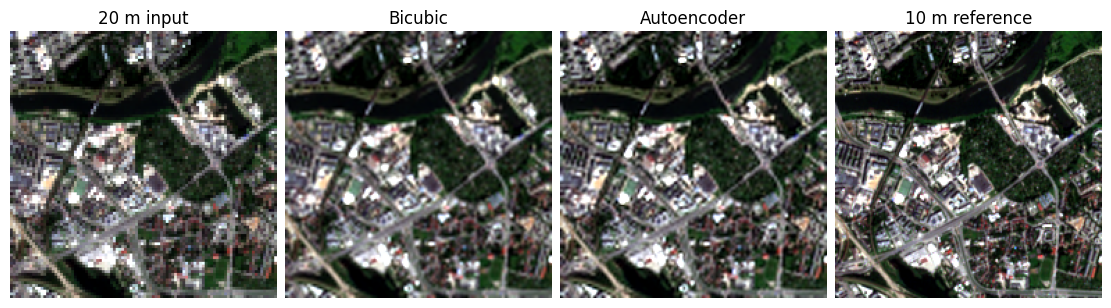

In [8]:
torch.manual_seed(SEED)
extra_model = Autoencoder()
extra_optimizer = torch.optim.Adam(extra_model.parameters(), lr=LEARNING_RATE)

for epoch in range(1, EXTRA_EPOCHS + 1):
    total_loss = 0.0
    for batch in torch.randperm(len(train_hr)).split(BATCH_SIZE):
        extra_optimizer.zero_grad()
        loss = F.l1_loss(extra_model(train_lr[batch]), train_hr[batch])
        loss.backward()
        extra_optimizer.step()
        total_loss += loss.item() * len(batch)
    if epoch == 1 or epoch % 50 == 0:
        print(f"Epoch {epoch:3d}: training MAE {total_loss / len(train_hr):.5f}")

extra_reference = image[None, :, 480:672, 440:632]
extra_lr = F.avg_pool2d(extra_reference, kernel_size=2)
extra_model.eval()
with torch.no_grad():
    extra_prediction = extra_model(extra_lr).clamp(0, 1)
extra_baseline = bicubic(extra_lr).clamp(0, 1)
print(f"Bicubic:     {psnr(extra_baseline, extra_reference):.2f} dB")
print(f"Autoencoder: {psnr(extra_prediction, extra_reference):.2f} dB")

extra_views = {
    "20 m input": F.interpolate(extra_lr, scale_factor=2, mode="nearest"),
    "Bicubic": extra_baseline,
    "Autoencoder": extra_prediction,
    "10 m reference": extra_reference,
}
fig, axes = plt.subplots(1, 4, figsize=(11, 3), layout="constrained")
for ax, (title, pixels) in zip(axes, extra_views.items()):
    ax.imshow(display_rgb(pixels, lo, hi))
    ax.set_title(title)
    ax.axis("off")
plt.show()

The autoencoder reached 37.88 dB on this crop, compared with 37.37 dB for bicubic. The training MAE fell from 0.00907 at 100 epochs to 0.00900 at 200 epochs

The new crop is different from the first test crop, so the scores don't show how much of the difference comes from training for longer. To check that, I'd compare both models on the same test crops. A separate acquisition would also help check how well the model works on another image